# DSC 411/511 Project
# Notebook 99: Summary: How I Moved Towards the Goals, What I Found, and References

This notebook collects the main results of notebooks 00-09 in one place. All tables below are **read from the files
that the earlier notebooks saved** (folder `tables/`), so the numbers are the real outputs, not copied by hand.

---
# Section 1: The Path of the Project

1. **Starting point.** Three research questions on NFIP claims alone. With NFIP data only, the answers were weak
   (for example, RQ1 ROC-AUC 0.715 on unseen storms, and only 0.675 when whole storms were held out).
2. **Idea.** A claim is the result of *a building* (NFIP) meeting *a flood* (not in NFIP). So I added data about the
   flood and the place: **PRISM** daily rain, **NOAA HURDAT2** storm tracks, distance to the **coast**, **ACS**
   neighbourhood data and the **FEMA National Risk Index**.
3. **Careful EDA and cleaning** (notebook 01): every dropped row, dropped column, placeholder and imputed value is
   logged; a dedicated leakage section removed outcome-related fields, including a hidden leak found during the work
   (replacement cost is blank mostly on unpaid claims).
4. **Feature reduction** (02) showed which data source carries information, and that PCA is not the right tool here.
5. **One notebook per question** (03-09): each starts from the class topic, explains the algorithm step by step,
   applies it with a **time split** (train 2020-2023, test 2024-2025) and an **event-grouped** cross-validation, and
   ends with "Research question -> Answer". Each one compares **NFIP-only vs NFIP + external data**.
6. **Published research** was reproduced where the data allowed it, then extended.

In [1]:
import json
import sys
import pandas as pd
from IPython.display import Image, display

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import TABLE_DIR, FIGURE_DIR

pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 80)

---
# Section 2: Data Actually Used

In [2]:
row_log = pd.read_csv(TABLE_DIR / '01_row_cleaning_log.csv')
print(row_log[['step', 'rows_removed', 'rows_after']].to_string(index=False))
cleaning_summary = json.load(open(TABLE_DIR / '01_cleaning_summary.json'))
print()
for key, value in cleaning_summary.items():
    print(f'{key:<35} {value}')
print()
print(pd.read_csv(TABLE_DIR / '00_external_join_coverage.csv').to_string(index=False))

                               step  rows_removed  rows_after
          0a. NFIP v3 national file             0     2725989
0b. loss date 2020-2025, CONUS only       2449925      276064
            1. exact duplicate rows           453      275611
    2. administrative error records         14528      261083
            3. no building coverage          6338      254745
           4. no latitude/longitude          1722      253023
    5. impossible building payments           613      252410

rows_after_cleaning                 252410
columns_after_cleaning              119
rows_removed_by_cleaning_steps      23654
columns_dropped                     30
columns_imputed                     35
placeholder_columns_fixed           11
large_loss_line_usd                 143213.60000000003

                           feature  non_missing_pct
                  rain_loss_day_mm            99.35
                      rain_3day_mm            99.35
                      rain_7day_mm            99.

| Source | What we took | Notes |
|---|---|---|
| OpenFEMA **NFIP Redacted Claims v3** (bulk parquet, 2,725,989 rows) | claims with loss date 2020-01-01 to 2025-12-31, CONUS | v3 is used because v2 is deprecated. 2025 is incomplete (reporting lag) |
| **PRISM** AN daily precipitation, 4 km (2,199 daily grids) | rain on loss day, 3-day and 7-day totals, max daily rain | PRISM day ends 12:00 UTC, so windows include day t+1; 3x3-cell mean around the 0.1-degree point |
| **NOAA HURDAT2** (Atlantic, 1851-2025) | nearest storm within +/- 3 days: distance, wind, Saffir-Simpson category | tracks interpolated to hourly; name matches FEMA's event label 98.9% |
| **Natural Earth** 10 m coastline | distance to coast | |
| **ACS 5-year 2019-2023** (Summary File tables B01003, B19013, B25077, B25003, B25035, C17002, B03002) | income, home value, % owner, median year built, % poverty, % non-Hispanic White, population | Census API now needs a key, so the bulk Summary File was used; block group 85%, tract 6%, county 8% |
| **FEMA National Risk Index v1.20** (counties) | coastal / riverine flood and hurricane risk, social vulnerability, resilience | matched for 99.4% of claims |
| **Census cartographic boundaries 2023** | county and state maps, Moran's I neighbours | |

| OpenFEMA **NFIP Redacted Policies v3** (74,778,941 records) | policies in force on 1 July 2020-2025, by census tract | used only in notebook 09 (take-up); v2 `FimaNfipPolicies` is deprecated |
| Census **2023 Gazetteer tracts**, **2020-2010 tract relationship file**, ACS tables **B25001, B25034** | tract points, moving 2010 codes to 2020 tracts, housing units, year built | notebook 09 |

Hawaii, Alaska and the territories are excluded because PRISM covers only the contiguous U.S.

---
# Section 3: Notebooks, Class Topics and Questions

| Notebook | Class topics | Question |
|---|---|---|
| 00 data acquisition and merging | L03 aggregation, sampling | Build one table: NFIP + PRISM + HURDAT2 + coast + ACS + NRI |
| 01 EDA and cleaning | L03 preprocessing, L13 outliers | What must be dropped, fixed, imputed? What would leak? |
| 02 feature reduction | L04 PCA, filters, mutual information | Can we reduce the features, and which source carries information? |
| 03 RQ1 positive building payment | L05 trees, naive Bayes; L06 k-NN; L07 logistic, SVM, evaluation; L14 MLP | Can building, policy and event data predict a positive payment? |
| 04 RQ2 large-loss flag | L07 imbalance, thresholds, ROC/PR | Can we flag damage above the P90 line before inspection? |
| 05 RQ3 clusters | L08 k-means, hierarchical; L09 DBSCAN; L10 validation; L16 autoencoder, t-SNE | Do building/policy features form meaningful groups? |
| 06 RQ4 association rules | L11 Apriori, FP-Growth; L12 lift, leverage, conviction, chi-squared | Which trait combinations travel with large losses? |
| 07 RQ5 rain vs surge, hotspots | L05 trees, L06 k-NN, L09 KDE and DBSCAN; spatial statistics | Is damage outside the SFHA rain-driven? Where are the hotspots? |
| 08 RQ6 equity | L07 logistic regression and odds; L03 discretization | Are lower-income areas paid less, after controlling for the flood? |
| 09 RQ7 protection gap | L03 aggregation; L05/07 tree regressor with grouped CV; L09-10 spatial clusters; count models; LISA | Do poorer, renter-heavy or older tracts file fewer claims per housing unit at the same hazard, and is it take-up? |

---
# Section 4: Key Results

## RQ1: positive building payment (notebook 03)

In [3]:
print(pd.read_csv(TABLE_DIR / '03_rq1_progression.csv').round(3).to_string(index=False))
print()
print(pd.read_csv(TABLE_DIR / '03_rq1_model_comparison.csv').round(3).to_string(index=False))

                            feature_set  n_features  LightGBM_ROC_AUC  LightGBM_PR_AUC_not_paid  Logistic_ROC_AUC
                           A. NFIP only          31             0.715                     0.356             0.697
B. NFIP + event (PRISM, HURDAT2, coast)          43             0.786                     0.434             0.682
   C. NFIP + event + context (ACS, NRI)          58             0.772                     0.430             0.696

                     model trained_on  ROC_AUC  PR_AUC_not_paid
             Dummy (prior)        all    0.500            0.131
   Decision tree (depth 8)        all    0.665            0.295
      Gaussian naive Bayes 30k sample    0.640            0.290
              k-NN (k=151) 30k sample    0.705            0.273
       Logistic regression        all    0.696            0.341
                 SVM (RBF) 30k sample    0.715            0.391
Neural network (MLP 64-32)        all    0.761            0.403
                  LightGBM     

**Answer.** Partly. NFIP-only LightGBM reaches ROC-AUC 0.715; adding PRISM rain, storm and coast data raises it to
0.786 and PR-AUC for "not paid" from 0.356 to 0.434 (random = 0.131). ACS/NRI does not help on the time split. The
first split of every tree is 3-day rain. The model is useful for triage, not for decisions.

## RQ2: large-loss flag (notebook 04)

In [4]:
print(pd.read_csv(TABLE_DIR / '04_rq2_progression.csv').round(3).to_string(index=False))
print()
print(pd.read_csv(TABLE_DIR / '04_rq2_state_vs_national.csv').round(3).to_string(index=False))

                            feature_set  ROC_AUC  PR_AUC  lift_top10%  precision@0.5  recall@0.5  Logistic_PR_AUC  Logistic_ROC_AUC
                           A. NFIP only    0.813   0.412        2.582          0.571       0.093            0.399             0.788
B. NFIP + event (PRISM, HURDAT2, coast)    0.807   0.455        2.957          0.747       0.064            0.377             0.777
   C. NFIP + event + context (ACS, NRI)    0.821   0.472        3.047          0.728       0.052            0.379             0.783

state  train_claims  test_claims  test_large_%  national_model_PR_AUC  state_model_PR_AUC  national_ROC_AUC  state_ROC_AUC
   FL         59551        70421        21.258                  0.493               0.482             0.790          0.782
   LA         21146         3041         2.861                  0.287               0.242             0.899          0.870
   TX          4187         6026         5.526                  0.259               0.197             

**Answer.** Yes, as a ranking tool. Line = $143,214 (P90 of positive damage, 2020-2023). NFIP-only already ranks
well (ROC 0.813), and external data improves PR-AUC 0.412 -> 0.472 and top-10% lift 2.6 -> 3.0. Ghaedi et al.'s
"state models beat national" was **not** reproduced at claim level.

## RQ3: building and policy clusters (notebook 05)

                                                               cluster_name  claims  building_paid_rate  large_loss_rate  median_paid_if_paid  median_damage_to_value  median_rain_3day
                                   C0: single-family homes, newer buildings   70229               0.784            0.055             16124.65                   0.054           157.053
                                                    C1: single-family homes  133244               0.872            0.117             51000.00                   0.259            98.138
C2: condo / multi-unit or commercial, high coverage, second homes / rentals   39167               0.796            0.261             69634.93                   0.105           123.563
                                                         C3: V-zone coastal    9770               0.788            0.183             29330.53                   0.069            85.237

        grouping            outcome  n_groups  chi2_p_value  cramers_V
        

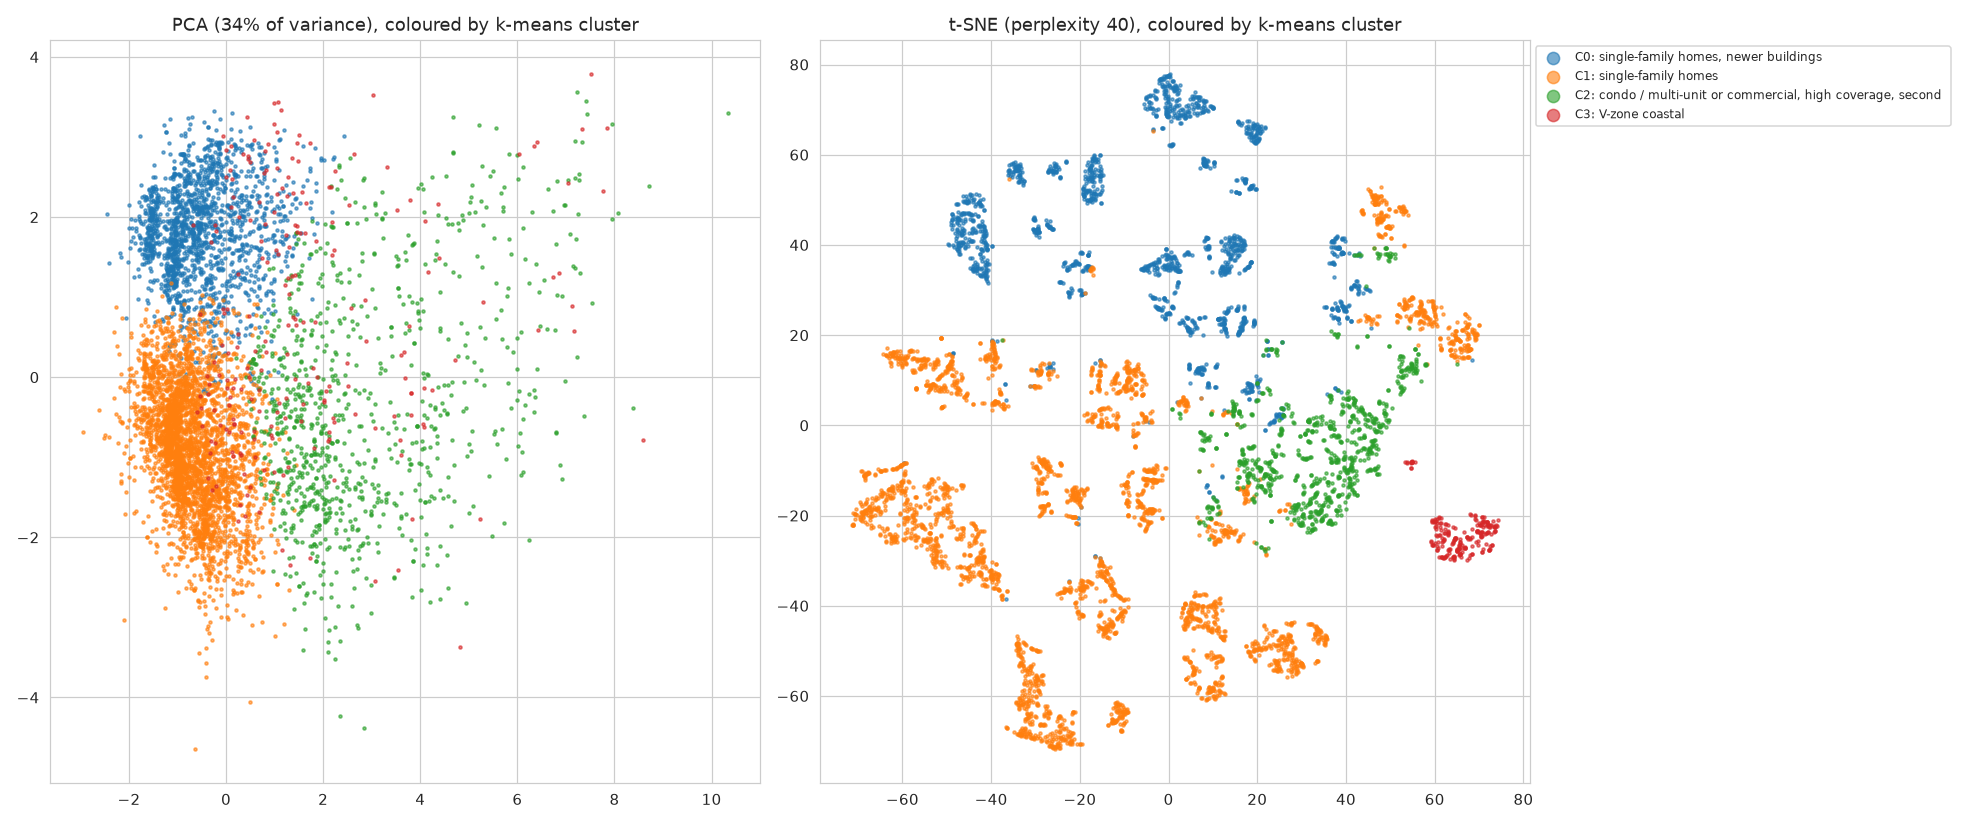

In [5]:
print(pd.read_csv(TABLE_DIR / '05_rq3_cluster_outcomes.csv').round(3).to_string(index=False))
print()
print(pd.read_csv(TABLE_DIR / '05_rq3_cluster_vs_outcome_association.csv').round(3).to_string(index=False))
display(Image(filename=str(FIGURE_DIR / '05_pca_tsne_by_cluster.png'), width=1000))

**Answer.** Four nameable groups (post-FIRM homes, older pre-FIRM homes, multi-unit/commercial, V-zone), clearly
above a noise baseline but only partly stable. Afterwards, they differ in large-loss rate (5.5% to 26.1%), but one
column (occupancy) separates outcomes as well.

## RQ4: association rules (notebook 06)

In [6]:
print(pd.read_csv(TABLE_DIR / '06_rq4_progression.csv').round(3).to_string(index=False))

       outcome         allowed items  n_rules  best_lift  mean_lift_top10  best_confidence
OUT_large_loss       NFIP items only      149      4.584            4.036            0.384
OUT_large_loss NFIP + external items      450      5.368            4.443            0.450
  OUT_not_paid       NFIP items only       96      1.836            1.678            0.355
  OUT_not_paid NFIP + external items      320      2.780            2.481            0.537


**Answer.** Condo/multi-unit + coverage at the cap + category 3+ storm -> large loss (lift 5.4 in training, about
2.1 on 2024-2025). Low rain + zone X -> not paid (lift 2.8, then 3.7 on the test years). External items raise the
best lift for both outcomes.

## RQ5: rain vs surge and hotspots (notebook 07)

                  model                             feature_set  macro_F1  balanced_accuracy
               LightGBM                            A. NFIP only     0.581              0.603
               LightGBM B. NFIP + event (PRISM, HURDAT2, coast)     0.581              0.620
               LightGBM    C. NFIP + event + context (ACS, NRI)     0.588              0.627
k-NN (k=51, 40k sample)                            A. NFIP only     0.493              0.482
k-NN (k=51, 40k sample) B. NFIP + event (PRISM, HURDAT2, coast)     0.518              0.508
  Decision tree depth 3       4 physical external features only     0.473              0.554

 hotspot  large_loss_claims  centre_lat  centre_lon  share_outside_SFHA_%  share_rain_cause_%  share_surge_cause_%                    main_event
       2            13630.0        27.7       -82.6                   1.3                46.8                 48.4              Hurricane Helene
       1             8588.0        26.4       -81.9       

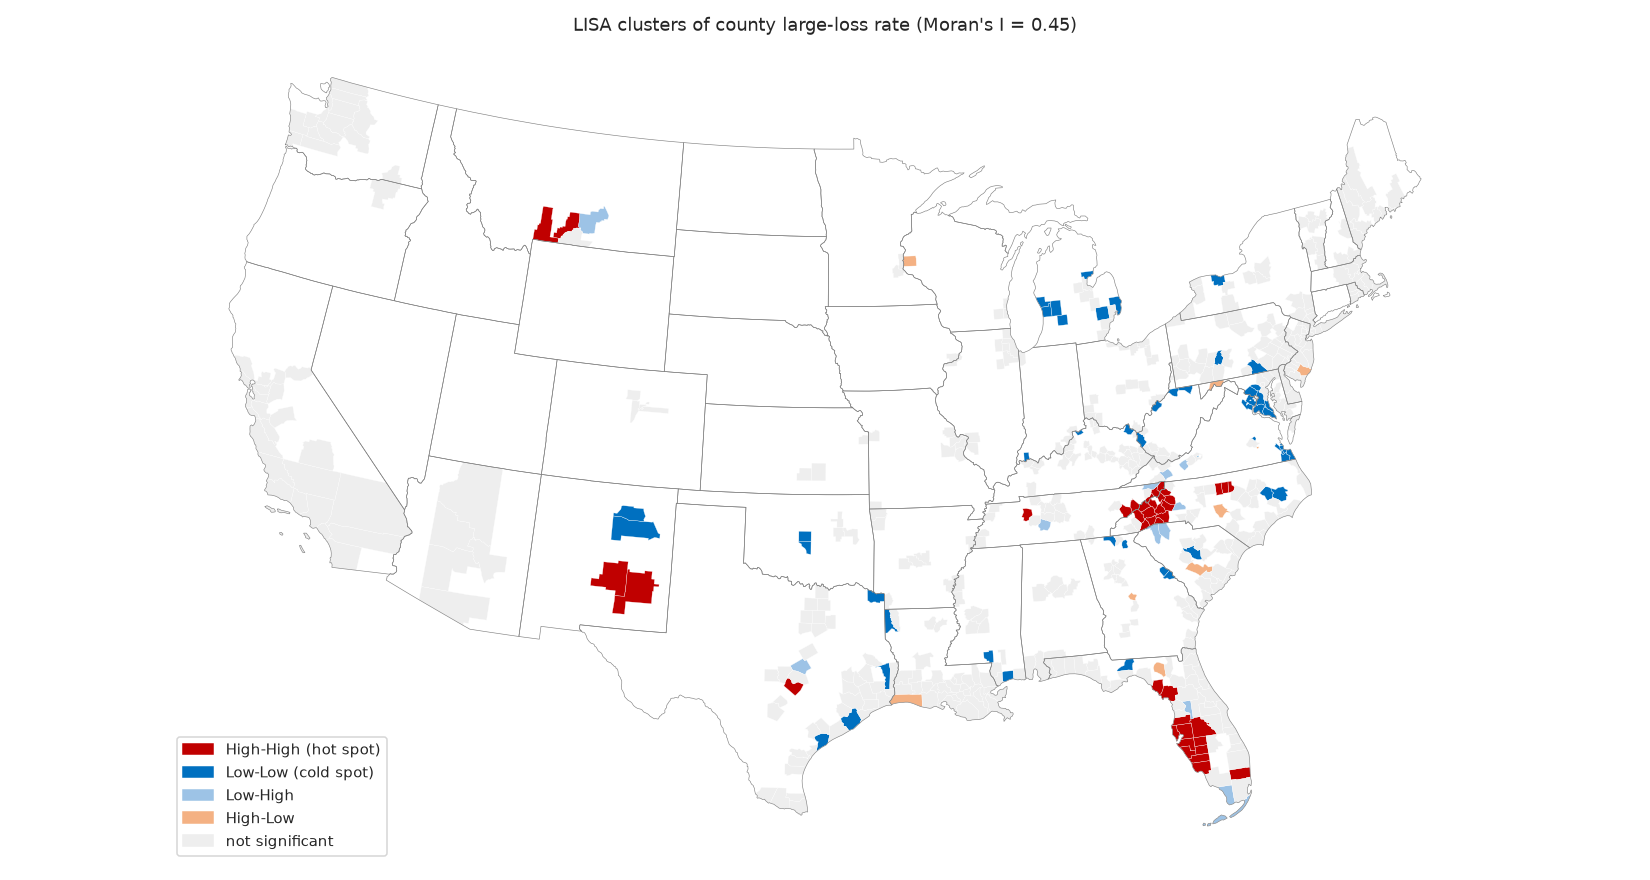

In [7]:
print(pd.read_csv(TABLE_DIR / '07_rq5_cause_models.csv').round(3).to_string(index=False))
print()
print(pd.read_csv(TABLE_DIR / '07_rq5_dbscan_hotspots.csv').round(1).head(10).to_string(index=False))
display(Image(filename=str(FIGURE_DIR / '07_lisa_large_loss.png'), width=1000))

**Answer.** (a) Outside the SFHA, 75.9% of rain/river/surge-coded claims are rain accumulation (Nelson-Mercer et
al.: 87.1% for 1978-2021); the share drops to 49.8% in 2022 (Ian). (b) The cause can be predicted only partly
(macro-F1 about 0.58), and external data adds nothing for LightGBM because lat/lon and flood zone already encode the
coast. (c) Large losses are strongly clustered: Moran's I = 0.45 (p = 0.002), 40 High-High counties; DBSCAN finds 8
storm hotspots, with Tampa Bay (Helene) and Fort Myers (Ian) holding 76% of hotspot claims; smaller urban
hotspots (Fort Lauderdale 2023, Louisiana, NY/NJ) are rain-driven with 10-30% of large losses outside the SFHA.

## RQ6: equity (notebook 08)

In [8]:
odds_ratios = pd.read_csv(TABLE_DIR / '08_rq6_nonpayment_odds_ratios.csv')
print(odds_ratios[odds_ratios['quintile'] == 'Q1_lowest'].round(3).to_string(index=False))

                           model  quintile  estimate  ci_low  ci_high  p_value
                          M1 raw Q1_lowest     1.358   1.035    1.781    0.027
            M2 + building/policy Q1_lowest     1.319   1.065    1.633    0.011
M3 + flood exposure, state, year Q1_lowest     1.283   1.044    1.576    0.018
            M4 + adjuster damage Q1_lowest     1.252   1.006    1.558    0.044


**Answer.** Lowest-income block groups have higher odds of a claim closing without payment (OR 1.36 raw, 1.25 after
controlling for building, policy, rain, storm, state, year and adjuster damage; 95% CI 1.01-1.56). About 73% of the
raw gap remains. The payment-per-dollar-of-damage gap is small (-1.4 points, not significant). Ecological, weak
evidence: a reason to look closer, not proof of unfair treatment.

## RQ7: protection gap (notebook 09)

                          model      variable (+1 SD)   IRR  ci_low  ci_high  p_value  tracts                      estimator
    (a) claims per housing unit            log_income 0.998   0.882    1.128    0.968   17370 negative binomial (alpha 2.73)
    (a) claims per housing unit            pct_renter 0.682   0.619    0.751    0.000   17370 negative binomial (alpha 2.73)
    (a) claims per housing unit pct_built_before_1980 1.278   1.139    1.433    0.000   17370 negative binomial (alpha 2.73)
(b) take-up (PIF 2020 per unit)            log_income 1.343   1.249    1.445    0.000   17370 negative binomial (alpha 1.05)
(b) take-up (PIF 2020 per unit)            pct_renter 0.857   0.805    0.912    0.000   17370 negative binomial (alpha 1.05)
(b) take-up (PIF 2020 per unit) pct_built_before_1980 1.018   0.963    1.076    0.535   17370 negative binomial (alpha 1.05)
 (c) claims per policy in force            log_income 0.825   0.650    1.046    0.112   13497        Poisson GLM (robust SE)


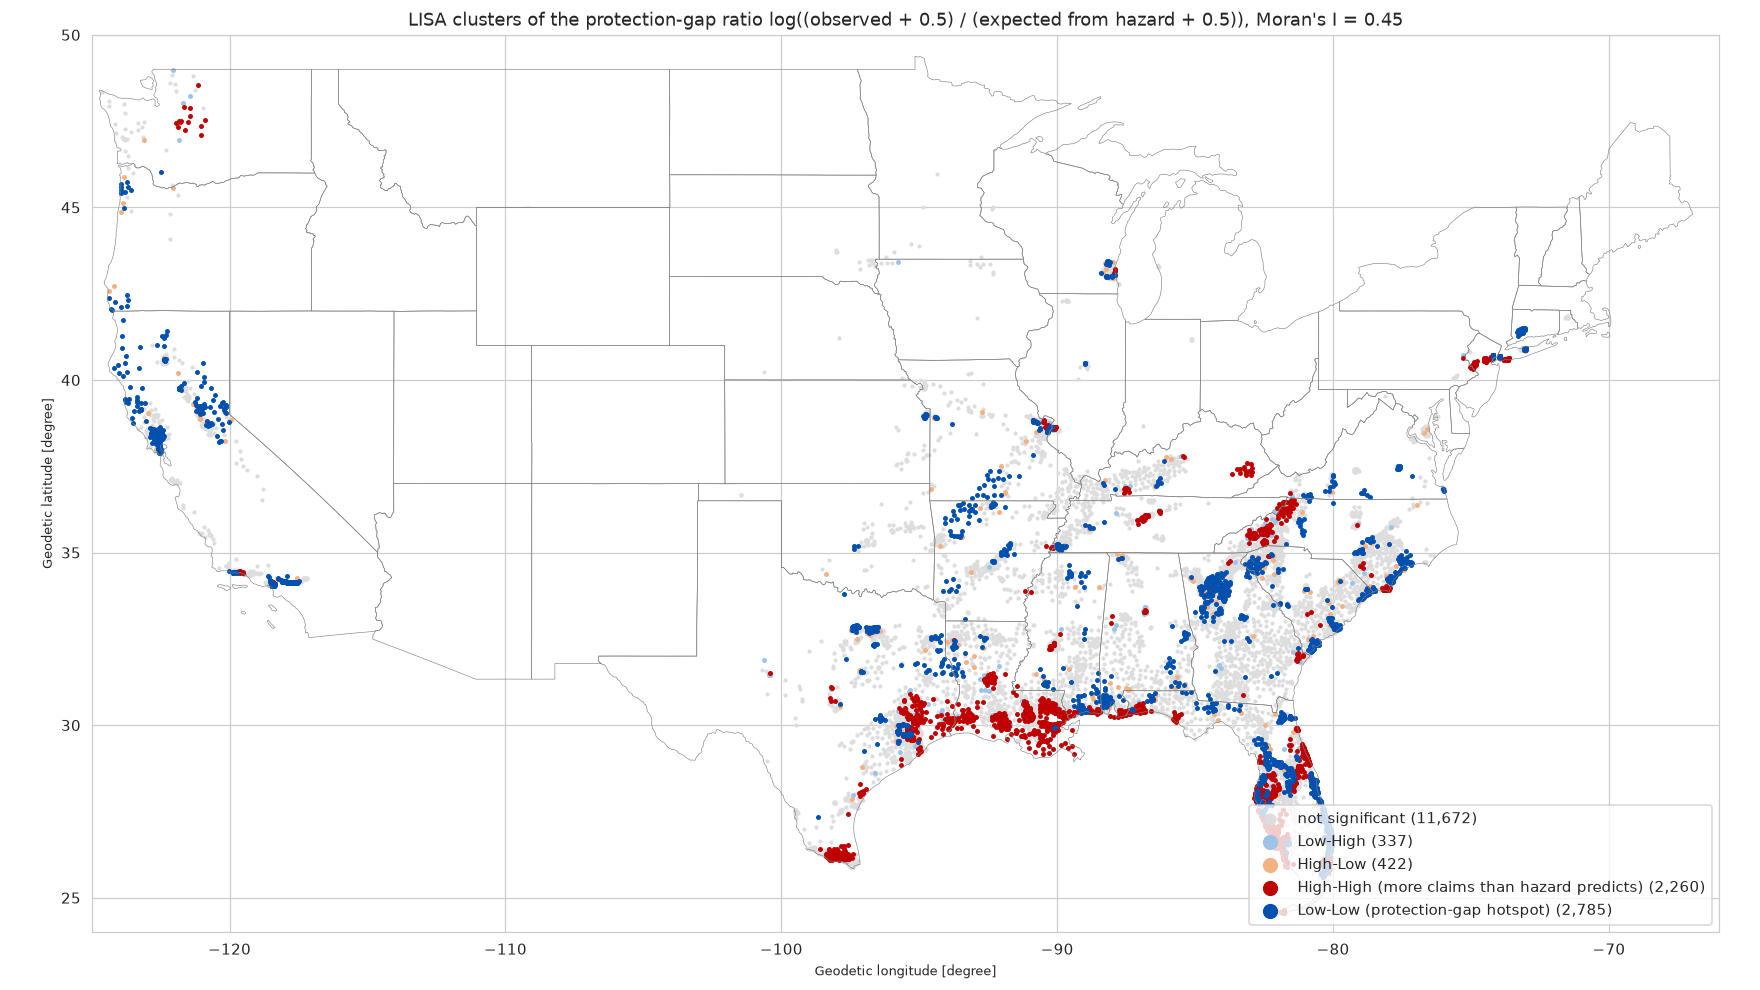

In [9]:
print(pd.read_csv(TABLE_DIR / '09_rq7_negative_binomial_irr.csv').round(3).to_string(index=False))
print()
print(pd.read_csv(TABLE_DIR / '09_rq7_lisa_profile.csv').round(2).to_string(index=False))
display(Image(filename=str(FIGURE_DIR / '09_rq7_lisa_protection_gap.png'), width=1000))

**Answer.** In 17,476 exposed tracts (hurricane within 100 km or >= 200 mm in 3 days), renter-heavy tracts file about one
third fewer claims per housing unit at the same hazard (IRR 0.68 per SD), through lower take-up (0.86) and fewer claims per
policy (0.78). Income has no net effect after hazard and state controls (IRR 1.00) because higher take-up in richer tracts
(1.34) and fewer claims per policy (0.83) cancel; in the highest-hazard band the poorest tracts insured 14.7% of units vs
44.9% in the richest. Older housing files more claims (1.28). The gap ratio is clustered (Moran's I = 0.45); 2,785 Low-Low
hotspot tracts filed about 1,700 claims where hazard predicted about 50,000, with 7.5% take-up, mostly inland heavy-rain areas.

---
# Section 5: What the External Data Changed (honest summary)

| Question | NFIP only | NFIP + external | Verdict |
|---|---|---|---|
| RQ1 paid (ROC / PR-AUC) | 0.715 / 0.356 | 0.786 / 0.434 (event) | **Clear gain** from rain and storm data |
| RQ2 large loss (ROC / PR-AUC / lift@10%) | 0.813 / 0.412 / 2.58 | 0.821 / 0.472 / 3.05 | **Gain in PR-AUC and lift**, small in ROC |
| RQ3 clusters (Cramer's V with large loss) | 0.198 | 0.237 (+ ACS, NRI, coast) | Small gain |
| RQ4 rules (best lift large loss / not paid) | 4.58 / 1.84 | 5.37 / 2.78 | **Gain** |
| RQ5 cause (LightGBM macro-F1) | 0.581 | 0.581-0.588 | **No gain** (lat/lon + zone already encode the coast) |
| Feature reduction (logistic, large loss) | 0.768 ROC | 0.750-0.782 | No gain for a *linear* model |
| RQ7 claims per housing unit (tract level) | not possible without hazard and census data | hazard explains 40% of deviance; ACS adds about 1 point | The question itself needs the external data and the policies file |

The external data helps where the outcome depends on **how hard the flood hit** (payment, large loss, rules). It does
not help where NFIP location fields already carry the same information, and it does not help linear models much.

---
# Section 6: Limitations

- Notebooks 03-08 model outcomes **given a claim**. Only notebook 09 uses the policies file (policies in force by tract) to look at who files claims at all; private flood insurance is never observed.
- Coordinates are rounded to 0.1 degree (about 11 km). Rain and coast distance are measured at that point.
- 2025 claims are incomplete (reporting lag). 2024 was dominated by Helene and Milton, so the test period is unusual.
- The adjuster's damage and cause are themselves estimates.
- ACS values describe neighbourhoods, not policyholders.

---
# Section 7: References

**Data**
1. FEMA. *OpenFEMA Dataset: FIMA NFIP Redacted Claims - v3*. https://www.fema.gov/openfema-data-page/nfip-redacted-claims-v3 (bulk file NfipClaimsV3.parquet, accessed 2026).
2. PRISM Climate Group, Oregon State University. *AN daily precipitation, 4 km*. https://prism.oregonstate.edu (data: https://data.prism.oregonstate.edu/time_series/us/an/4km/ppt/daily/).
3. Landsea, C. W. & Franklin, J. L. (2013). Atlantic hurricane database uncertainty and presentation of a new database format (HURDAT2). *Monthly Weather Review* 141, 3576-3592. Data: https://www.nhc.noaa.gov/data/hurdat/
4. U.S. Census Bureau. *American Community Survey 2019-2023 5-year estimates, Summary File*. https://www2.census.gov/programs-surveys/acs/summary_file/2023/
5. U.S. Census Bureau. *2023 Cartographic Boundary Files (counties, states)*. https://www2.census.gov/geo/tiger/GENZ2023/
6. FEMA. *National Risk Index, v1.20, county table*. https://www.fema.gov/flood-maps/products-tools/national-risk-index
7. Natural Earth. *1:10m coastline*. https://www.naturalearthdata.com

**Published research reproduced or extended**
8. Nelson-Mercer, B., Kim, T., Tran, V. N. & Ivanov, V. (2025). Pluvial flood impacts and policyholder responses throughout the United States. *npj Natural Hazards*. https://www.nature.com/articles/s44304-025-00058-7 (reproduced in notebook 07).
9. Ghaedi, H., Reilly, A. C., Baroud, H., Perrucci, D. V. & Ferreira, C. M. (2022). Predicting flood damage using the flood peak ratio and Giovanni Flooded Fraction. *PLOS ONE* 17(8). https://pmc.ncbi.nlm.nih.gov/articles/PMC9348728/ (reproduced in notebook 04).
10. Urban Institute. *Housing Resilience in Greater New Orleans*. https://www.urban.org/research/publication/housing-resilience-greater-new-orleans (finding repeated in notebook 08).
11. *Are Underserved Populations Left Out of National Flood Mitigation Efforts and Facing Greater Impact? A Method to Assess Racial Inequality at the Census Tract Level* (2023). *Journal of Climate Resilience and Justice* 1, 78-92. https://research.utwente.nl/en/publications/are-underserved-populations-left-out-of-national-flood-mitigation/ (notebook 08).
12. Kousky, C. & Michel-Kerjan, E. (2017). Examining flood insurance claims in the United States: Six key findings. *Journal of Risk and Insurance* 84(3), 819-850. https://doi.org/10.1111/jori.12106 (features and payment determinants, notebooks 01, 03).
13. Salas, J., Saha, A. & Ravela, S. (2023). Learning inter-annual flood loss risk models from historical flood insurance claims. *Journal of Environmental Management* 347, 118862. https://doi.org/10.1016/j.jenvman.2023.118862 (rain added to NFIP; gradient boosting; notebooks 03-04).
14. Bowers, C., Serafin, K. A. & Baker, J. W. (2024). Uncovering drivers of atmospheric river flood damage using interpretable machine learning. *Natural Hazards Review* 25(3). https://doi.org/10.1061/nhrefo.nheng-1995 (storm + exposure features, SHAP-style interpretation).
15. Liu, C. & Mostafavi, A. (2025). FloodGenome: interpretable machine learning for property flood-risk predisposition. *Environmental Research: Infrastructure and Sustainability*. https://doi.org/10.1088/2634-4505/adb800 (clustering of flood-risk features, notebook 05).
16. Liu, C.-F., Huang, L., Yin, K., Brody, S. & Mostafavi, A. (2024). FloodDamageCast: building flood damage nowcasting with machine learning and data augmentation. *International Journal of Disaster Risk Reduction*. https://doi.org/10.1016/j.ijdrr.2024.104971
17. Kraft, L. L., Villarini, G., Czajkowski, J., Zimmerman, D. & Amorim, R. S. (2025). Developing a spatial regression model framework for insured flood losses in Houston. *ASCE OPEN* 3(1). https://ascelibrary.org/doi/10.1061/AOMJAH.AOENG-0044 (Moran's I, notebook 07).
18. Stacked ensemble approach for predicting residential flood insurance claims across Indiana (2020). AGU Fall Meeting abstract. https://studio.m-anage.com/agu/fm20/webprogram/Paper760856.html (adjusted R2 about 0.22: the problem is hard).

18b. Amornsiripanitch, N., Biswas, S., Orellana-Li, J. & Zink, D. (2025). Measuring flood underinsurance in the USA. *Nature Climate Change* 15. https://www.nature.com/articles/s41558-025-02396-w (notebook 09).
18c. FEMA. *OpenFEMA Dataset: FIMA NFIP Redacted Policies - v3*. https://www.fema.gov/openfema-data-page/nfip-redacted-policies-v3 (notebook 09).
18d. U.S. Census Bureau. *2020 Census Tract to 2010 Census Tract Relationship File* and *2023 Gazetteer Files*. https://www.census.gov/geographies/reference-files/time-series/geo/relationship-files.html (notebook 09).

**Context: NFIP policy and pricing**
19. Mulder, P. & Kousky, C. (2023). Risk Rating without information provision. *AEA Papers and Proceedings* 113, 299-303. https://www.aeaweb.org/articles?id=10.1257/pandp.20231102 (Risk Rating 2.0, notebook 01).
20. Gourevitch, J., Snyder, M. & Kousky, C. (2025). Effects of risk-based pricing reform on flood insurance uptake. *Journal of Catastrophe Risk and Resilience*. https://journalofcrr.com/research/03-07-gourevitch-et-al/
21. Ortega, F. & Petkov, I. (2025). To improve is to change? The effects of Risk Rating 2.0 on flood insurance demand. *Journal of Environmental Economics and Management* 134, 103228. https://docs.iza.org/dp17021.pdf
22. Bradt, J., Kousky, C. & Wing, O. (2021). Voluntary purchases and adverse selection in the market for flood insurance. *Journal of Environmental Economics and Management* 110, 102515. https://doi.org/10.1016/j.jeem.2021.102515
23. U.S. GAO (2023). *National Flood Insurance Program: FEMA's new rate-setting methodology...* GAO-23-105977. https://www.gao.gov/products/gao-23-105977

**Methods**
24. Pedregosa, F. et al. (2011). Scikit-learn: machine learning in Python. *JMLR* 12, 2825-2830.
25. Ke, G. et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS*.
26. Lundberg, S. M. & Lee, S.-I. (2017). A unified approach to interpreting model predictions (SHAP). *NeurIPS*.
27. van der Maaten, L. & Hinton, G. (2008). Visualizing data using t-SNE. *JMLR* 9, 2579-2605.
28. Ester, M., Kriegel, H.-P., Sander, J. & Xu, X. (1996). A density-based algorithm for discovering clusters (DBSCAN). *KDD*.
29. Agrawal, R. & Srikant, R. (1994). Fast algorithms for mining association rules. *VLDB*. Han, J., Pei, J. & Yin, Y. (2000). Mining frequent patterns without candidate generation (FP-Growth). *SIGMOD*.
29b. Cameron, A. C. & Trivedi, P. K. (2013). *Regression Analysis of Count Data* (2nd ed.). Cambridge University Press (Poisson / negative binomial, notebook 09).
30. Anselin, L. (1995). Local indicators of spatial association - LISA. *Geographical Analysis* 27(2), 93-115.
31. Raschka, S. (2018). MLxtend. *Journal of Open Source Software* 3(24), 638. Rey, S. J. & Anselin, L. (2007). PySAL. 